In [1]:
import pandas as pd
import numpy as np
import os
import glob
from tqdm import tqdm
import json
from joblib import Parallel, delayed

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.cm as cm
import matplotlib.colors as mcolors

import seaborn as sns

import nibabel as nib

import nilearn.plotting as plotting

from scipy.stats import pearsonr, ttest_ind, mannwhitneyu, zscore, sem, f_oneway

from utils import rewrite_subjectID, process_data, correct_OS, load_maps

%load_ext autoreload
%autoreload 2

In [2]:
voxel_res = 1.5
root =  "/home/joan/Desktop/PROJECTS/Glioblastomas" # "D:\JoanFR_Sano"
os.makedirs(root, exist_ok=True)
MNI_DIR = "/home/joan/Documents/MNI_ICBM_2009b_NLIN_ASYM" # "C:/Users/user/Documents/Data/MNI"
atlas_lobes = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labelxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
lobe_labels = f"/home/joan/Documents/Parcellation/USCLobesMNI-ICBM-2009b-NLIN-ASYM/BCI-DNI_brain.labels.txt"
atlas_wm = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/xtract-tract-atlases-maxprob5-1mmxMNI-ICBM-2009b-NLIN-ASYM__Warped.nii.gz"
WM_labels = f"/home/joan/Documents/Parcellation/XTRACT_MNI-ICBM-2009b-NLIN-ASYM/XTRACT.labels.txt"
T1_file = os.path.join(MNI_DIR, f"T1_{voxel_res}mm.nii")
T1 = nib.load(T1_file)
T1_brain = nib.load(os.path.join(MNI_DIR, f"T1_{voxel_res}mm_brain_mask.nii"))

Ni, Nj, Nk = T1.get_fdata().shape
ucsf_dir = "Glioblastoma_UCSF-PDGM_v3-20230111"
upenn_dir = "Glioblastoma_UPENN-GBM_v2-20221024"
tissue = "whole"
tdmap = "TDMap-lesion"

## Other
fmt = "svg"
dpi = 300
stream_th = 0
daysXmonth = 365/12
voxel_size = (0.5**3) * (1/1000) # 0.5 (mm³/voxel) X 0.001 (cm³/mm³)   
sites = [0, 1]
n_jobs = 16
nthreads = 2

In [4]:
## Load and process clinical data
DATA = correct_OS(
    process_data(
        root,
        stream_th,
        voxel_size,
        UCSF_dir=ucsf_dir,
        UPENN_dir=upenn_dir,
        z_transform=0,
        cohort_ids=sites
    ),
    cohort_ids=sites,
    n_perms=10
)

# Process and load UCSF maps
ucsf_ids = [rewrite_subjectID(id) for id in DATA.loc[DATA["site"]==0]["ID"].values]
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{ucsf_dir}/TDMaps_Grade-IV",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(ucsf_ids, desc="Loading UCSF maps")
)
maps_ucsf = np.vstack(results) # Nsubjects x nFeatures
maps_ucsf = np.where(maps_ucsf>=0, maps_ucsf, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

Log-rank test: chi-squared statistic of 0.11102525773640061 (p=0.7389799001044497)
INFO: The effect of site was NOT found to be significant, copying OS data as it was


Loading UCSF maps:   0%|          | 0/367 [00:00<?, ?it/s]

Loading UCSF maps: 100%|██████████| 367/367 [00:08<00:00, 44.31it/s]


In [5]:
# Process and load UPENN maps
upenn_ids = DATA.loc[DATA["site"]==1]["ID"].values
results = Parallel(n_jobs=n_jobs)(
    delayed(load_maps)(
        list_of_subjects=[subj_id],
        nFeatures=Ni * Nj * Nk,
        template=T1_file,
        root=root,
        data_dir=f"{upenn_dir}/TDMaps_IDH1-WT",
        tissue=tissue,
        tdmap=tdmap,
        voxel_res=voxel_res,
        nthreads=nthreads
    ) for subj_id in tqdm(upenn_ids, desc="Loading UPENN maps")
)
maps_upenn = np.vstack(results) # Nsubjects x nFeatures
maps_upenn = np.where(maps_upenn>=0, maps_upenn, 0) # The resampling has introduced some small amount of negative numbers ## Be careful and double check

maps_all = np.vstack((maps_ucsf, maps_upenn))

Loading UPENN maps:   0%|          | 0/496 [00:00<?, ?it/s]

Loading UPENN maps: 100%|██████████| 496/496 [00:08<00:00, 56.81it/s]


In [7]:
from dataclasses import dataclass, field


@dataclass
class Dataset:
    name: str
    path: str
    maps: np.ndarray
    df: pd.DataFrame

    def __str__(self):
        return self.name.upper()
    
from typing import TypeAlias, Union
from KernelPCA import TD_Kernel_PCA
from TractDensityComponents import TD_PCA
from nmf import NMFProjections


Projector: TypeAlias = Union[TD_Kernel_PCA, TD_PCA, NMFProjections]

class Transformer:
    def __init__(self, projector: Projector):
        self.projector = projector

    def fit_transform(self, norm, **kwargs):
        return self.projector.fit_transform_maps(norm=norm, **kwargs)
    
    def transform(self, maps):
        return self.projector.transform_maps(maps)
# class Transformer:
#     def __init__(self, projector):
#         self.projector = projector
#         # self.is_fitted = False

#     def fit(self, norm, **kwargs):
#         self.projector.fit(norm=norm, **kwargs)
#         # self.is_fitted = True
#         return self

#     def transform(self, maps):
#         # if not self.is_fitted:
#             # raise RuntimeError("First call fit() or fit_transform()!")
#         return self.projector.transform_maps(maps)

#     def fit_transform(self, norm, **kwargs):
#         """Trenuje i od razu transformuje (dla zbioru treningowego)."""
#         # Możesz to zrobić elegancko, wywołując własne metody:
#         # self.fit(norm=norm, **kwargs)
#         # Zauważ, że fit w TD_VAE zazwyczaj używa self.training_maps, 
#         # więc transformujemy te same dane, na których się uczyliśmy.
#         return self.transform(self.projector.training_maps)
    
from lifelines import CoxPHFitter


class TD_CoxPHFitter:
    def __init__(self, penalizer: float | int = 0.01,):
        self.penalizer = penalizer
        self._cph = CoxPHFitter(penalizer=penalizer)
    
    def fit(self, X_train: pd.DataFrame, duration_col: str, event_col: str, **kwargs):
        self._cph.fit(X_train, duration_col, event_col=event_col, **kwargs)

    def score(self, X_test: pd.DataFrame, scoring_method: str = "log_likelihood", **kwargs):
        return self._cph.score(X_test, scoring_method, **kwargs)
    
    def plot(self, ax):
        self._cph.plot(ax=ax)
    
    @property
    def concordance_index(self):
        if not hasattr(self._cph, "concordance_index_"):
            raise ValueError("CoxPHFitter not fitted yet. Fit it first")
        return self._cph.concordance_index_
    
    @property
    def cph(self):
        return self._cph
    
from dataclasses import dataclass
import matplotlib.pyplot as plt

@dataclass
class ModelConfig:
    penalizer: float = 0.01
    duration_col: str = 'OS (corrected)'
    event_col: str = 'status'
    n_components: int = 100

from enum import Enum

from pipeline_encoder import EncodingPipeline


class DataTransformer:
    class FeatureMethod(Enum):
        COSINE = "Cos"
        RBF = "RBF"
        PCA = "PCA"
        NMF = "NMF"

    COMPONENT_PREFIX = "Comp"
    COLUMNS_TO_DROP = ["volume", "site", "OS", "ID", "ltdi", "tdi"]
    NUMERICAL_COLUMNS_TO_DROP = ["OS (corrected)", "status"]

    @staticmethod
    def add_extracted_mapsdata(df_base: pd.DataFrame, extracted_features: np.ndarray, method: FeatureMethod, n_components: int, column_names: list[str] | None = None) -> pd.DataFrame:
        if column_names is None:
            column_names = [f"{method.value}_{DataTransformer.COMPONENT_PREFIX}_{i+1}" for i in range(n_components)]
        
        df_new_features = pd.DataFrame(
            extracted_features,
            columns=column_names, 
            index=df_base.index
        )

        df_all = pd.concat([df_base, df_new_features], axis=1)

        return df_all
    
    @staticmethod
    def drop_columns(df_base: pd.DataFrame):
        columns_to_drop = DataTransformer.COLUMNS_TO_DROP
        df_base = df_base.drop(columns=columns_to_drop)

        return df_base
    
    @staticmethod
    def feature_fit_transform(encoding_pipeline: EncodingPipeline):
        df_base = encoding_pipeline.df
        
        categorical_features = df_base.select_dtypes(include="object").columns
        numerical_features = df_base.select_dtypes(exclude="object").columns

        numerical_features = numerical_features.drop(DataTransformer.NUMERICAL_COLUMNS_TO_DROP)

        X_transformed = encoding_pipeline.fit_transform(list(numerical_features), list(categorical_features))

        return X_transformed
    

    @staticmethod
    def feature_transform(test_df: pd.DataFrame, encoding_pipeline: EncodingPipeline):
        X_transformed = encoding_pipeline.transform(test_df)
        
        return X_transformed


## Datasets

In [8]:
UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_training = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
# dataset_testing = Dataset("ucsf+upenn", "path/3", maps_all, DATA)

ucsf+upenn training Concordance Index: 0.6602
ucsf+upenn testing Concordance Index: 0.6602


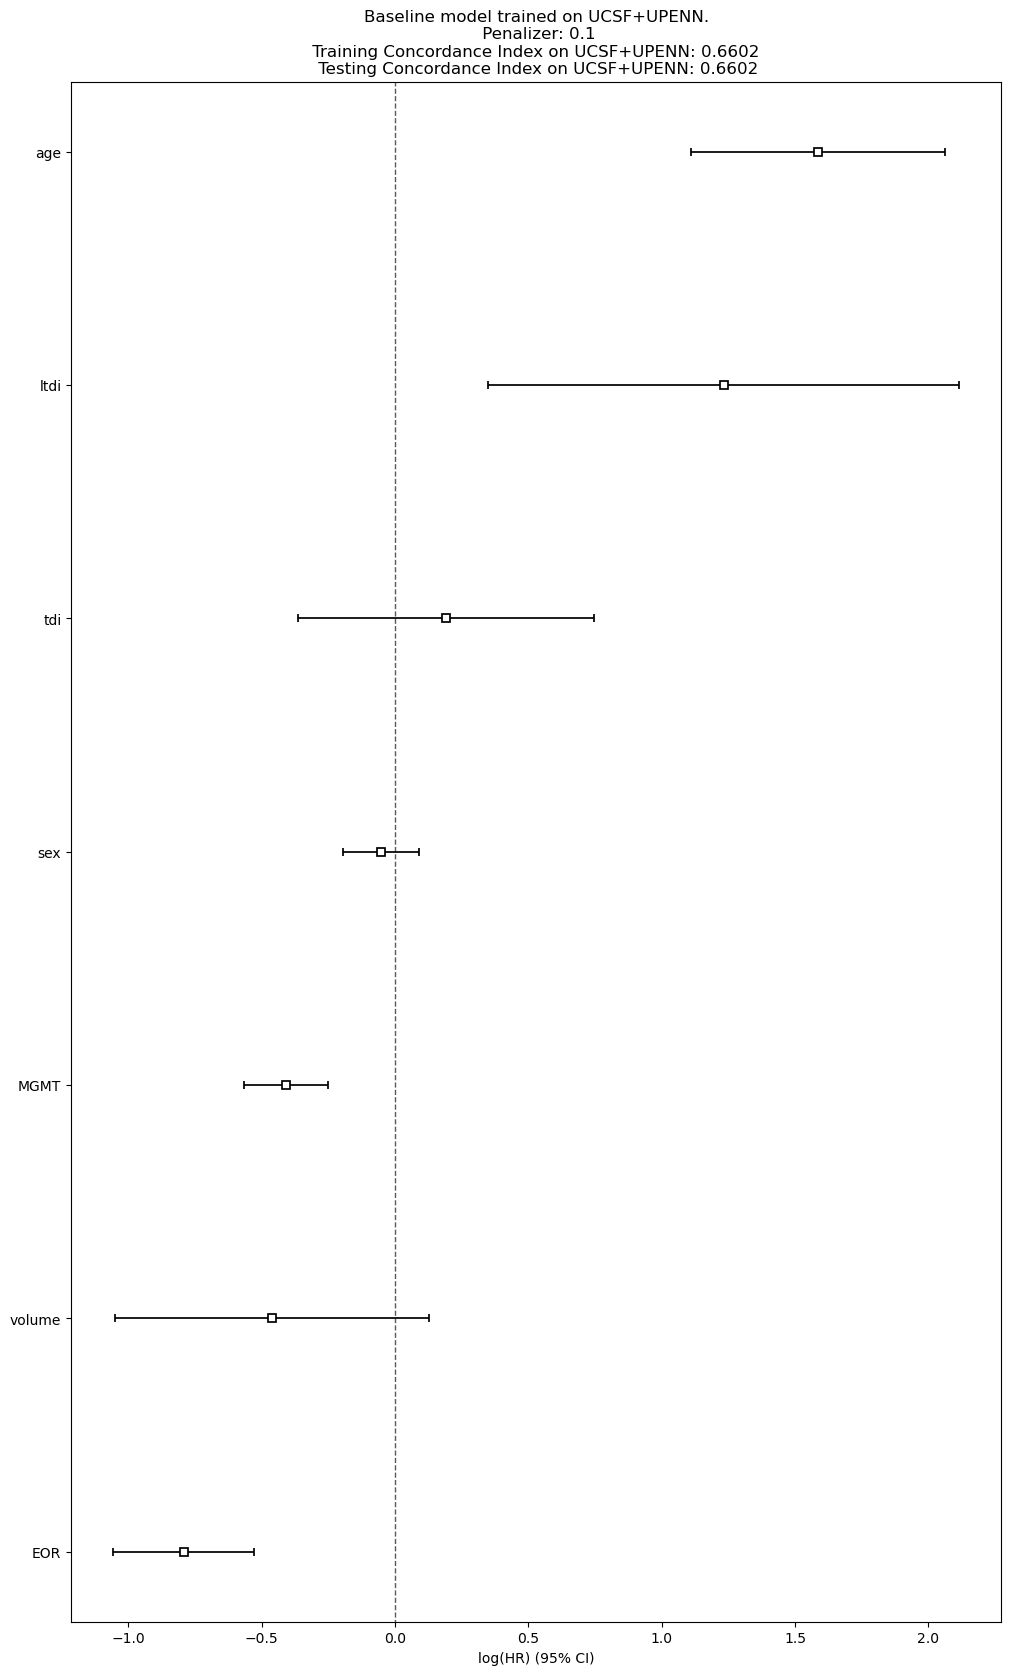

In [ ]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections

import sklearn

normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

# dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)
dataset_training = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
dataset_testing = Dataset("ucsf+upenn", "path/3", maps_all, DATA)

df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps


df_base = df_training
df_base = df_base.drop(columns=["OS", "site"])

encoding_pipeline = EncodingPipeline(df_base)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)


td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site"])
X_test = DataTransformer.feature_transform(df_base, encoding_pipeline)

c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"Baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
td_cphfitter.plot(ax = ax)

ucsf+upenn training Concordance Index: 0.6136
ucsf+upenn testing Concordance Index: 0.6136


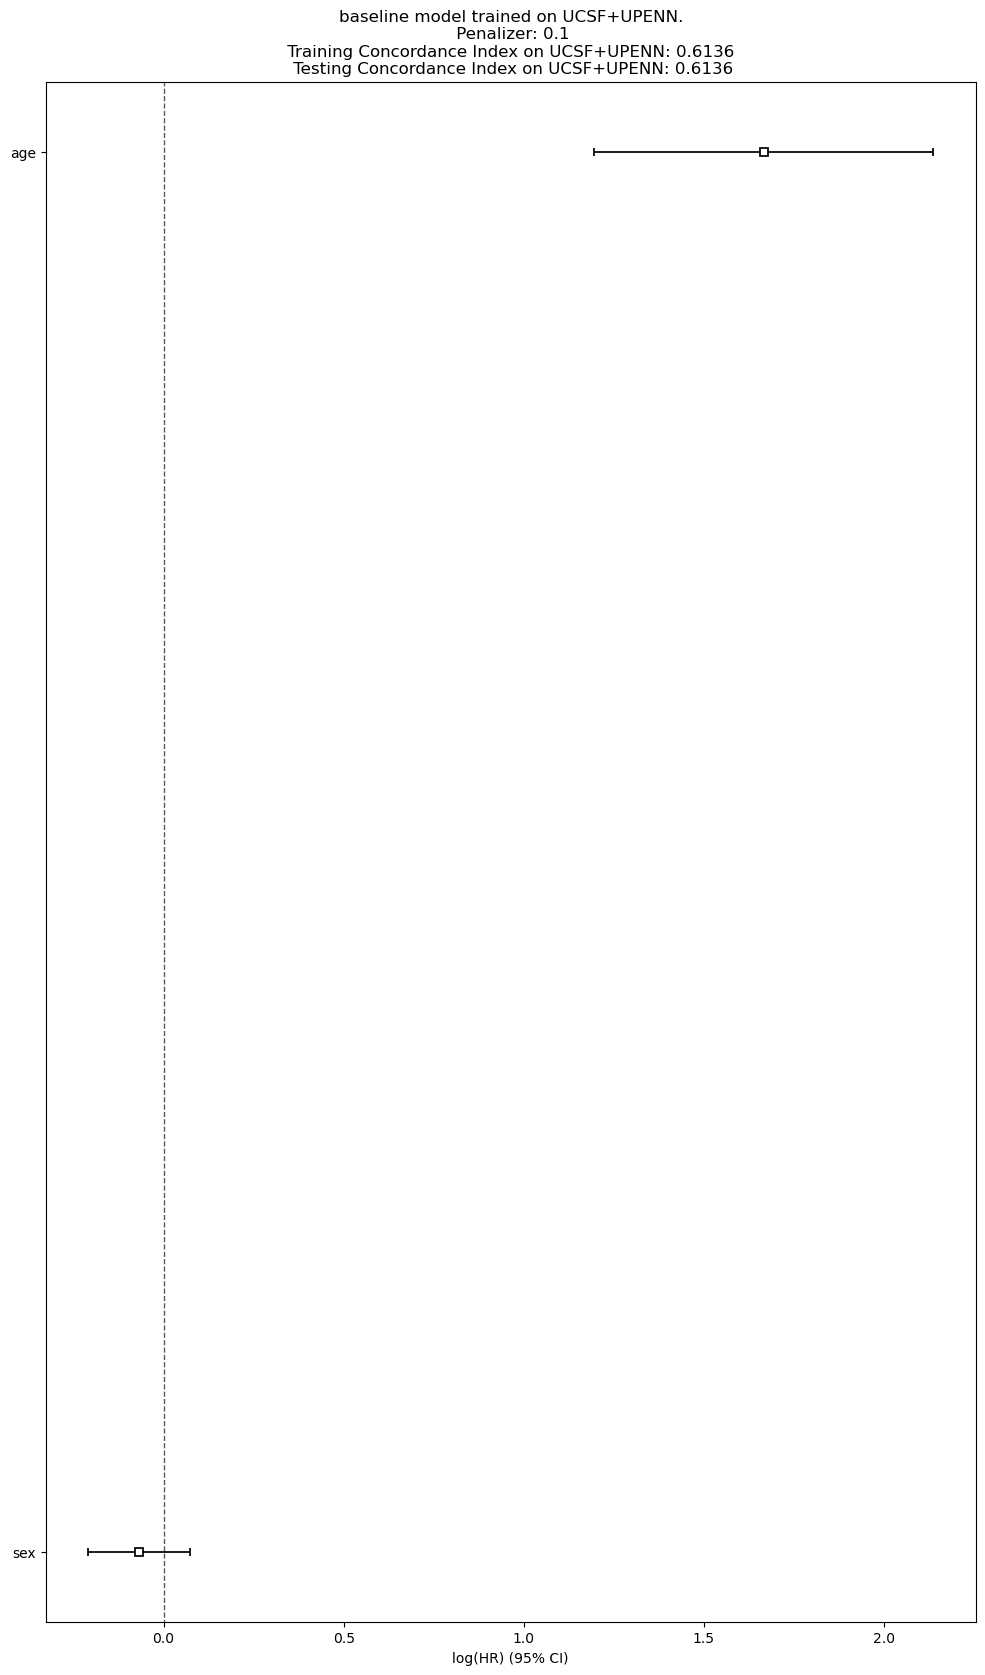

In [ ]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections

import sklearn

normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

# dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)
dataset_training = Dataset("ucsf+upenn", "path/3", maps_all, DATA)
dataset_testing = Dataset("ucsf+upenn", "path/3", maps_all, DATA)


df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps


df_base = df_training
df_base = df_base.drop(columns=["OS", "site", "EOR", "MGMT", "volume", "tdi", "ltdi"])


encoding_pipeline = EncodingPipeline(df_base)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)


td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site", "EOR", "MGMT", "volume", "tdi", "ltdi"])
X_test = DataTransformer.feature_transform(df_base, encoding_pipeline)

c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
td_cphfitter.plot(ax = ax)

INFO:	TD maps were masked.
INFO:	Training PCA without normalization . . .
INFO:	Principal Components (PCs) found successfully!
INFO:	TD maps were masked.
INFO:	Transforming maps without applying any normalization . . .
INFO:	Maps transformed sucessfully!
ucsf training Concordance Index: 0.7851
upenn testing Concordance Index: 0.5932


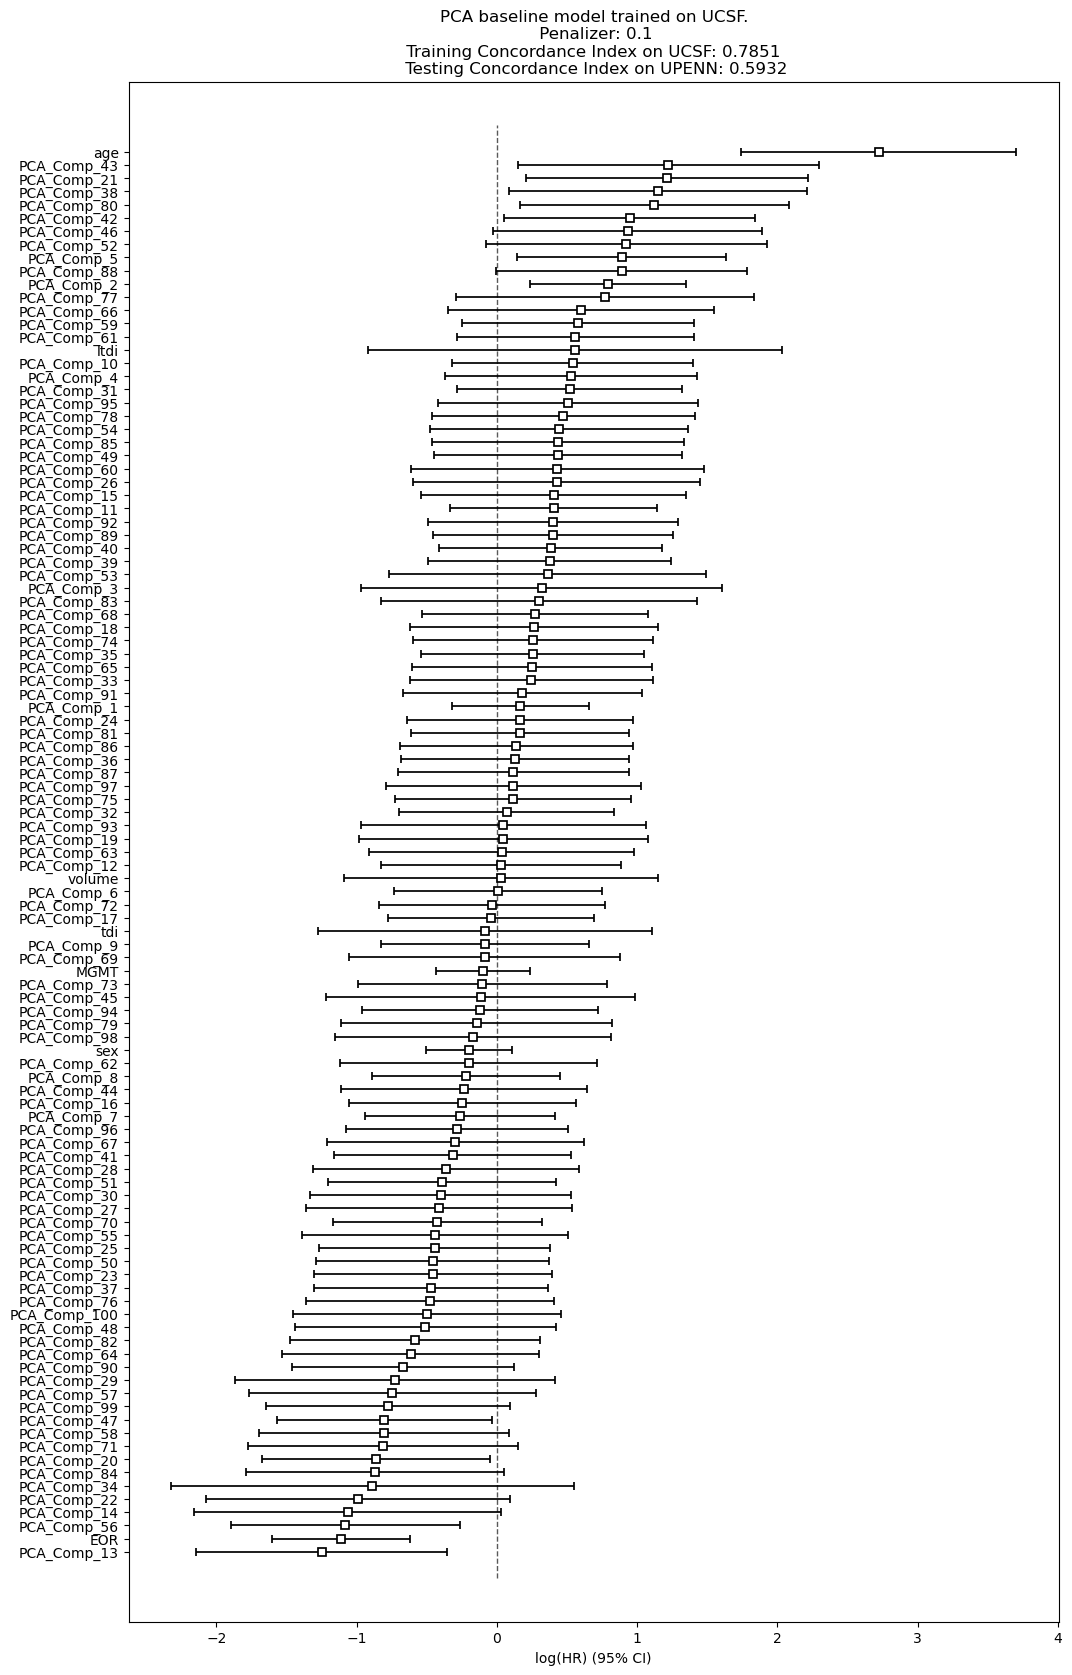

In [114]:
from TractDensityComponents import TD_PCA
from components import Projections
from nmf import NMFProjections

import sklearn

normalization = None#'min_max'
# save_dir = "results/"
n_components = 100

sklearn.set_config(transform_output="default")

UCSF_SITE_IDX = 0
UPENN_SITE_IDX = 1

data_ucsf = DATA[DATA['site'] == UCSF_SITE_IDX].copy()
data_upenn = DATA[DATA['site'] == UPENN_SITE_IDX].copy()

penalizer = 0.1
duration_col = 'OS (corrected)'
event_col = 'status'

dataset_training = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
dataset_testing = Dataset("upenn", "path/2", maps_upenn, data_upenn)
# dataset_testing = Dataset("ucsf", "path/1", maps_ucsf, data_ucsf)
# dataset_training = Dataset("upenn", "path/2", maps_upenn, data_upenn)

df_training = dataset_training.df
df_testing = dataset_testing.df

training_maps = dataset_training.maps
testing_maps = dataset_testing.maps

# method = TD_Kernel_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components, kernel='cosine', gamma=0.1)
method = TD_PCA(training_maps, T1, binary_mask=T1_brain, n_components=n_components)
# method = NMFProjections(training_maps, template=T1, binary_mask=T1_brain, n_components=n_components, max_iter=10)
trainer = Transformer(method)

comps_training = trainer.fit_transform(norm=normalization)
comps_testing = trainer.transform(testing_maps)

df_base = df_training
df_base = df_base.drop(columns=["OS", "site"])


X_train_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_training, method, n_components=n_components)
# df_base = DataTransformer.drop_columns(X_train_with_features)
encoding_pipeline = EncodingPipeline(X_train_with_features)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)


td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")

df_base = df_testing
df_base = df_base.drop(columns=["OS", "site"])
# X_test_with_features = DataHelper.add_extracted_mapsdata(df_base, comps_testing, method, n_components)
# X_test = DataHelper.feature_transform(X_test_with_features, )
X_test_with_features = DataTransformer.add_extracted_mapsdata(df_base, comps_testing, method, n_components=n_components)
X_test = DataTransformer.feature_transform(X_test_with_features, encoding_pipeline)

c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(f"{method} baseline model trained on {dataset_training.name.upper()}.\n Penalizer: {penalizer}\n Training Concordance Index on {dataset_training.name.upper()}: {td_cphfitter.concordance_index:.4f} \n Testing Concordance Index on {dataset_testing.name.upper()}: {c_index_test:.4f}")
td_cphfitter.plot(ax = ax)

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import torch
from nilearn import plotting, image

# Zakładam, że te klasy są dostępne w Twoim środowisku
from normalize import Normalizations
from masking_new import MaskingNew

# class VAE_Net(nn.Module):
#     def __init__(self, input_dim, latent_dim):
#         super(VAE_Net, self).__init__()
        
#         # Encoder: Kompresja danych do parametrów rozkładu Gaussa
#         self.encoder = nn.Sequential(
#             nn.Linear(input_dim, 512),
#             nn.ReLU(),
#             nn.Linear(512, 256),
#             nn.ReLU()
#         )
#         self.fc_mu = nn.Linear(256, latent_dim)
#         self.fc_logvar = nn.Linear(256, latent_dim)
        
#         # Decoder: Rekonstrukcja mapy z przestrzeni ukrytej
#         self.decoder = nn.Sequential(
#             nn.Linear(latent_dim, 256),
#             nn.ReLU(),
#             nn.Linear(256, 512),
#             nn.ReLU(),
#             nn.Linear(512, input_dim),
#             nn.Sigmoid() # Używamy Sigmoid, jeśli dane są w zakresie [0, 1]
#         )

#     def reparameterize(self, mu, logvar):
#         std = torch.exp(0.5 * logvar)
#         eps = torch.randn_like(std)
#         return mu + eps * std

#     def forward(self, x):
#         h = self.encoder(x)
#         mu, logvar = self.fc_mu(h), self.fc_logvar(h)
#         z = self.reparameterize(mu, logvar)
#         return self.decoder(z), mu, logvar

import torch
import torch.nn as nn
import torch.nn.functional as F

class VAE_Net(nn.Module):
    def __init__(self, input_dim, latent_dim, dropout_p=0.5):
        """
        Poprawiony VAE_Net z warstwą Dropout.
        dropout_p: prawdopodobieństwo wyłączenia neuronu (domyślnie 0.5)
        """
        super(VAE_Net, self).__init__()
        
        # Encoder: Dodajemy Dropout, aby zapobiec overfittingowi (Twoje 0.70 vs 0.53)
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Dropout(dropout_p), # Losowo wyłącza 50% neuronów
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout_p)  # Druga warstwa regularyzacji
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        
        # Decoder: Dekoder zazwyczaj nie potrzebuje Dropout, bo 
        # przestrzeń ukryta jest już "wąskim gardłem" (bottleneck).
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, input_dim),
            nn.Sigmoid() # Wymaga danych wejściowych w [0, 1]
        )

    def reparameterize(self, mu, logvar):
        """Standardowa technika reparametryzacji dla VAE."""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

class TD_VAE(Normalizations, MaskingNew):
    def __init__(self, training_maps, template, binary_mask=None, latent_dim=10, dropout_p=0.5, device='cpu'):
        # Inicjalizacja maskowania i parametrów obrazu
        self.shape = template.get_fdata().shape
        self.template = template
        self.latent_dim = latent_dim
        self.device = torch.device(device)

        MaskingNew.__init__(self, binary_mask, self.shape)
        
        if binary_mask is not None:
            self.training_maps = self.mask(np.array(training_maps))
            print("INFO:\tTD maps were masked.")
        else:
            self.training_maps = np.array(training_maps)

        Normalizations.__init__(self, self.training_maps)
        
        self.input_dim = self.training_maps.shape[1]
        self.model = VAE_Net(self.input_dim, latent_dim, dropout_p=dropout_p).to(self.device)

    # def _vae_loss(self, recon_x, x, mu, logvar, beta=1.0):
    #     # MSE mierzy błąd rekonstrukcji
    #     recon_loss = nn.functional.mse_loss(recon_x, x, reduction='sum')
    #     # KL Divergence mierzy "odległość" rozkładu ukrytego od N(0,1)
    #     # kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    #     kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - torch.exp(logvar))

    #     logvar = torch.clamp(logvar, min=-10, max=10)
    #     total_loss = recon_loss + (beta * kld_loss)
    #     return total_loss

        # return recon_loss + (beta * kld_loss)
    def _vae_loss(self, recon_x, x, mu, logvar, beta=1.0):
        # MSE: błąd rekonstrukcji
        recon_loss = nn.functional.mse_loss(recon_x, x, reduction='sum')
        
        # KLINCZ: Zabezpieczenie przed NaN (logvar nie może być za duży ani za mały)
        logvar = torch.clamp(logvar, min=-10, max=10)
        
        # KLD: Wzór musi być stabilny numerycznie
        kld_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - torch.exp(logvar))
        
        # Beta-VAE: beta > 1 pomaga w niezależności komponentów (lepsze dla Coxa)
        return recon_loss + (beta * kld_loss)

    def fit(self, epochs=100, batch_size=16, lr=1e-3, norm='min_max', beta=1.0):
        """Trenuje model VAE."""
        self.norm = norm
        if norm == 'min_max':
            self._train_MinMax()
            train_data = self.MinMaxmaps
        elif norm == 'z_norm':
            self._train_Zscore()
            train_data = self.Zmaps
        else:
            train_data = self.training_maps

        # Przygotowanie danych do PyTorch
        tensor_x = torch.Tensor(train_data).to(self.device)
        dataloader = DataLoader(TensorDataset(tensor_x), batch_size=batch_size, shuffle=True)
        
        optimizer = optim.Adam(self.model.parameters(), lr=lr)
        self.model.train()

        print(f"INFO:\tStarting VAE training for {epochs} epochs...")
        
        for epoch in range(epochs):
            train_loss = 0
            for batch in dataloader:
                x_batch = batch[0]
                optimizer.zero_grad()
                
                recon_batch, mu, logvar = self.model(x_batch)
                loss = self._vae_loss(recon_batch, x_batch, mu, logvar, beta=beta)
                
                loss.backward()
                # train_loss += loss.item()
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                optimizer.step()
            
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs}, Loss: {train_loss / len(train_data):.4f}")

    # def transform_maps(self, maps):
    #     """Mapuje dane do przestrzeni ukrytej (latent space)."""
    #     self.model.eval()
    #     maps = np.array(maps)
    #     if hasattr(self, "mask_flat"):
    #         maps = self.mask(maps)
            
    #     # Aplikacja normalizacji
    #     if self.norm == 'min_max':
    #         maps = self.MinMax(maps)
    #     elif self.norm == 'z_norm':
    #         maps = self.Zscore(maps)

    #     with torch.no_grad():
    #         tensor_maps = torch.Tensor(maps).to(self.device)
    #         mu, _ = self.model.encode_only(tensor_maps) # Musimy dodać tę pomocniczą metodę
    #         return mu.cpu().numpy()
    # def transform_maps(self, maps):
    #     self.model.eval()
    #     maps = np.array(maps)
        
    #     if maps.ndim == 1:
    #         maps = maps.reshape(1, -1)

    #     # LOGIKA NAPRAWCZA:
    #     # Sprawdzamy, czy liczba kolumn zgadza się z tym, co widziała sieć (input_dim)
    #     if maps.shape[1] != self.input_dim:
    #         # Jeśli dane są surowe (duże), spróbujmy je zamaskować
    #         if hasattr(self, "mask_flat") and maps.shape[1] > self.input_dim:
    #             print(f"INFO:\tAttempting to mask data from {maps.shape[1]} to {self.input_dim}...")
    #             maps = self.mask(maps)
    #         else:
    #             # Jeśli nadal się nie zgadza, rzucamy błąd, ale z lepszym opisem
    #             raise ValueError(f"Dane wejściowe mają {maps.shape[1]} cech, "
    #                              f"ale model VAE został zbudowany dla {self.input_dim} cech. "
    #                              f"Upewnij się, że używasz tej samej maski co przy fit().")

    #     # Kontynuacja (normalizacja i VAE)
    #     if not hasattr(self, "norm"):
    #         raise RuntimeError("Najpierw wywołaj fit().")

    #     if self.norm == 'min_max':
    #         maps_proc = self.MinMax(maps)
    #     elif self.norm == 'z_norm':
    #         maps_proc = self.Zscore(maps)
    #     else:
    #         maps_proc = maps

    #     with torch.no_grad():
    #         tensor_maps = torch.Tensor(maps_proc).to(self.device)
    #         mu, _ = self.encode_only(tensor_maps)
    #         return mu.cpu().numpy()
    def transform_maps(self, maps):
        self.model.eval()
        maps = np.nan_to_num(np.array(maps), nan=0.0) # Usuwamy ewentualne NaN z danych
        
        if maps.ndim == 1:
            maps = maps.reshape(1, -1)

        # Inteligentne sprawdzanie wymiarów
        if maps.shape[1] > self.input_dim:
            # Jeśli dane są surowe (pełny mózg), maskujemy
            maps_proc = self.mask(maps)
        elif maps.shape[1] == self.input_dim:
            # Dane są już zamaskowane, zostawiamy jak są
            maps_proc = maps
        else:
            raise ValueError(f"Niezgodność wymiarów: {maps.shape[1]} vs {self.input_dim}")

        # Normalizacja (musisz użyć tych samych parametrów co przy treningu!)
        if self.norm == 'min_max':
            maps_proc = self.MinMax(maps_proc)
        
        maps_proc = np.clip(maps_proc, 0, 1) # Sigmoid w dekoderze tego wymaga

        with torch.no_grad():
            tensor_maps = torch.Tensor(maps_proc).to(self.device)
            h = self.model.encoder(tensor_maps)
            mu = self.model.fc_mu(h)
            return mu.cpu().numpy()

    def __str__(self):
        return f"VAE(latent_dim={self.latent_dim})"
    
    @property
    def value(self):
        return "VAE"
    

    def encode_only(self, x):
        """Pomocnicza metoda, której brakowało w transform_maps"""
        h = self.model.encoder(x)
        mu = self.model.fc_mu(h)
        return mu, None
    
    def transform(self, maps):
        """Alias wymagany przez klasę Transformer"""
        return self.transform_maps(maps)

    def fit_transform_maps(self, norm='min_max', **kwargs):
        """
        Poprawiony alias: obsługuje teraz dowolną liczbę argumentów 
        przekazanych z trainer.fit_transform (np. epochs, batch_size)
        """
        self.fit(norm=norm, **kwargs) 
        return self.transform_maps(self.training_maps)
    
    def decode_maps(self, latent_vectors):
            """Dekoduje wektory ukryte z powrotem do przestrzeni voxelowej (zamaskowanej)."""
            self.model.eval()
            with torch.no_grad():
                # Przenosimy dane na odpowiednie urządzenie (CPU/CUDA)
                tensor_latent = torch.Tensor(latent_vectors).to(self.device)
                # Dekoder jest wbudowany w metodę forward, ale możemy go wywołać bezpośrednio
                # recon_flat, _, _ = self.model(tensor_latent) 
                # Zakładając standardową strukturę:
                recon_flat = self.model.decoder(tensor_latent)
                return recon_flat.cpu().numpy()

    def unmask_maps(self, flat_maps):
        """Przechodzi z płaskiej macierzy (latent/recon) do pełnego kształtu 3D."""
        # 1. Wykorzystujemy istniejącą metodę unmask z klasy MaskingNew
        # flat_maps: (n_subjects, n_masked_voxels)
        # Zwróci: (n_subjects, n_total_voxels)
        full_data_flat = self.unmask(flat_maps) 

        # 2. Zmieniamy kształt z płaskiego wektora na kostkę 3D dla każdego pacjenta
        n_subjects = flat_maps.shape[0]
        # Wynik: (n_subjects, X, Y, Z)
        unmasked_3d = full_data_flat.reshape((n_subjects,) + self.shape)
        
        return unmasked_3d

    def visualize_anatomical(self, map_single, title="VAE Reconstruction"):
        """
        Generuje anatomiczne przekroje (osiowe, strzałkowe, czołowe) 
        oryginalnej i zrekonstruowanej mapy, nakładając je na szablon T1.
        
        map_single: pojedyncza mapa 3D (np. z training_maps[0])
        """
        # 1. Przygotowanie danych (płaszczenie i normalizacja jak przy treningu)
        # Przyjmujemy, że map_single jest surowa (nie spłaszczona)
        map_flat = self.mask(map_single.reshape(1, -1))
        
        # Sigmoid na końcu dekodera VAE wymaga danych wejściowych [0, 1]
        input_norm = np.clip(self.MinMax(map_flat), 0, 1)

        # 2. Generowanie rekonstrukcji (transform -> decode)
        self.model.eval()
        with torch.no_grad():
            tensor_input = torch.Tensor(input_norm).to(self.device)
            recon_norm_flat, mu, _ = self.model(tensor_input)

        # 3. Odmaskowanie (powrót do 3D: Subjects x X x Y x Z)
        # unmask_maps oczekuje macierzy (1 x N_voxels)
        recon_3d_all = self.unmask_maps(recon_norm_flat.cpu().numpy())
        orig_3d_all = self.unmask_maps(map_flat) # Oryginał bez normalizacji, żeby widzieć gęstość włókien

        # Wyciągamy pierwszy (i jedyny) podmiot
        recon_3d = recon_3d_all[0]
        orig_3d = orig_3d_all[0]

        # 4. Tworzenie obiektów Nifti (wymagane przez nilearn do nałożenia na anatomię)
        # Używamy affine z szablonu template, żeby mapy były w tej samej przestrzeni
        affine = self.template.affine
        orig_img = nib.Nifti1Image(orig_3d, affine)
        recon_img = nib.Nifti1Image(recon_3d, affine)

        # 5. Rysowanie używając nilearn.plotting
        # Automatycznie znajdujemy najciekawsze przekroje (cut_coords) o najwyższej gęstości
        cut_coords = plotting.find_xyz_cut_coords(orig_img, activation_threshold=orig_3d.max()*0.5)

        fig, axes = plt.subplots(2, 1, figsize=(12, 10))
        
        # Góra: Oryginał
        plotting.plot_roi(orig_img, bg_img=self.template, cut_coords=cut_coords, 
                          title=f"Original Tract Density Map", 
                          axes=axes[0], cmap='hot', alpha=0.7)
        
        # Dół: Rekonstrukcja VAE
        # Nilearn automatycznie przeskaluje kolory, żeby pasowały
        plotting.plot_roi(recon_img, bg_img=self.template, cut_coords=cut_coords, 
                          title=f"VAE Reconstruction (latent_dim={self.latent_dim})", 
                          axes=axes[1], cmap='hot', alpha=0.7)
        
        plt.suptitle(title, fontsize=16)
        plt.show()
        
        # Opcjonalnie: Wydrukuj wektor ukryty (mu) dla tego pacjenta
        print(f"Wektor ukryty (Latent mu) dla tego pacjenta (pierwsze 10 dim):\n{mu.cpu().numpy()[0,:10]}")

In [17]:
n_components=32
method = TD_VAE(
    training_maps=training_maps, 
    template=T1, 
    binary_mask=T1_brain, 
    latent_dim=n_components,
    dropout_p=0.3,
    device='cuda'
)

method.fit(epochs=5, batch_size=4, lr=1e-5, norm='min_max', beta=4)

INFO:	TD maps were masked.
INFO:	Starting VAE training for 5 epochs...


In [18]:
trainer = Transformer(method)

comps_training = trainer.fit_transform(norm='min_max', epochs=5) 
comps_testing = trainer.transform(testing_maps)

INFO:	Starting VAE training for 5 epochs...


In [14]:
df_base = df_training

X_train_with_features = DataTransformer.add_extracted_mapsdata(
    df_base, comps_training, method, n_components=n_components
)

upenn training Concordance Index: 0.6320
ucsf testing Concordance Index: 0.6300


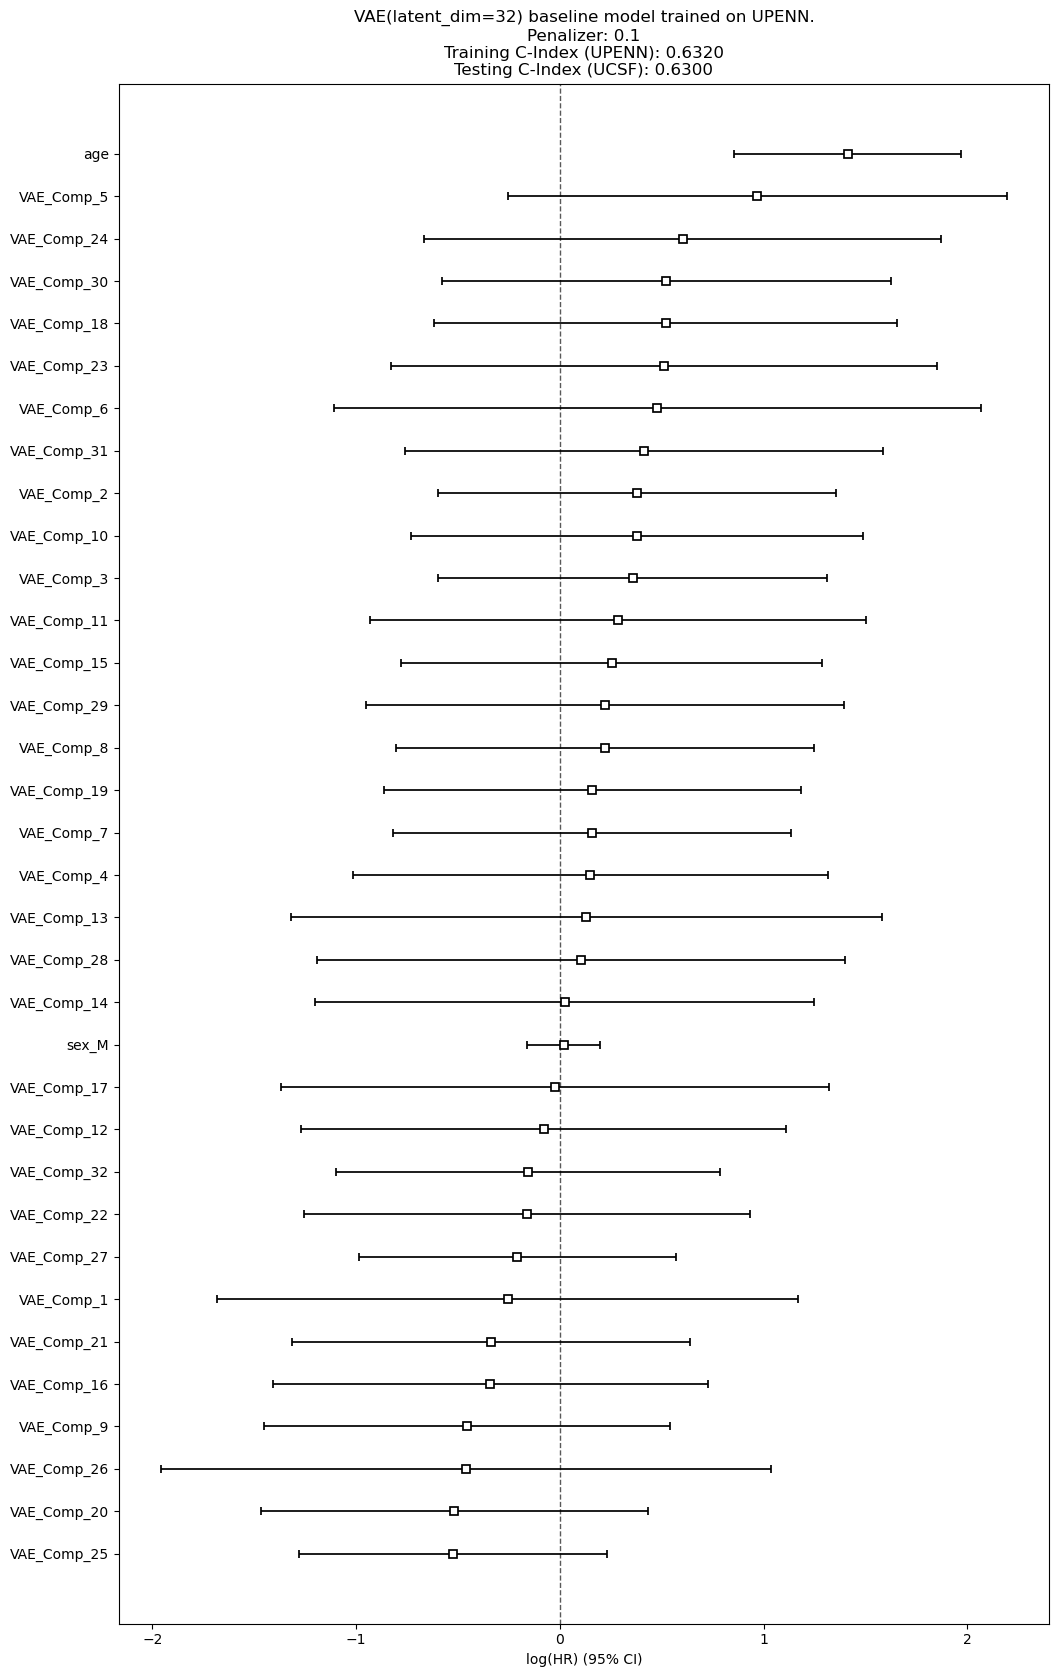

In [19]:

df_base = df_training

X_train_with_features = DataTransformer.add_extracted_mapsdata(
    df_base, comps_training, method, n_components=n_components
)

df_train_prepped = DataTransformer.drop_columns(X_train_with_features)
encoding_pipeline = EncodingPipeline(df_train_prepped)
X_train = DataTransformer.feature_fit_transform(encoding_pipeline)


penalizer = 0.1

td_cphfitter = TD_CoxPHFitter(penalizer)
td_cphfitter.fit(X_train, duration_col, event_col)

print(f"{dataset_training.name} training Concordance Index: {td_cphfitter.concordance_index:.4f}")


X_test_with_features = DataTransformer.add_extracted_mapsdata(
    dataset_testing.df, comps_testing, method, n_components=n_components
)

df_test_prepped = DataTransformer.drop_columns(X_test_with_features)
X_test = DataTransformer.feature_transform(df_test_prepped, encoding_pipeline)


c_index_test = td_cphfitter.score(X_test, "concordance_index")
print(f"{dataset_testing.name} testing Concordance Index: {c_index_test:.4f}")

fig, ax = plt.subplots(figsize=(12, 20))
ax.set_title(
    f"{method} baseline model trained on {dataset_training.name.upper()}.\n"
    f"Penalizer: {penalizer}\n"
    f"Training C-Index ({dataset_training.name.upper()}): {td_cphfitter.concordance_index:.4f}\n"
    f"Testing C-Index ({dataset_testing.name.upper()}): {c_index_test:.4f}"
)
td_cphfitter.plot(ax=ax)

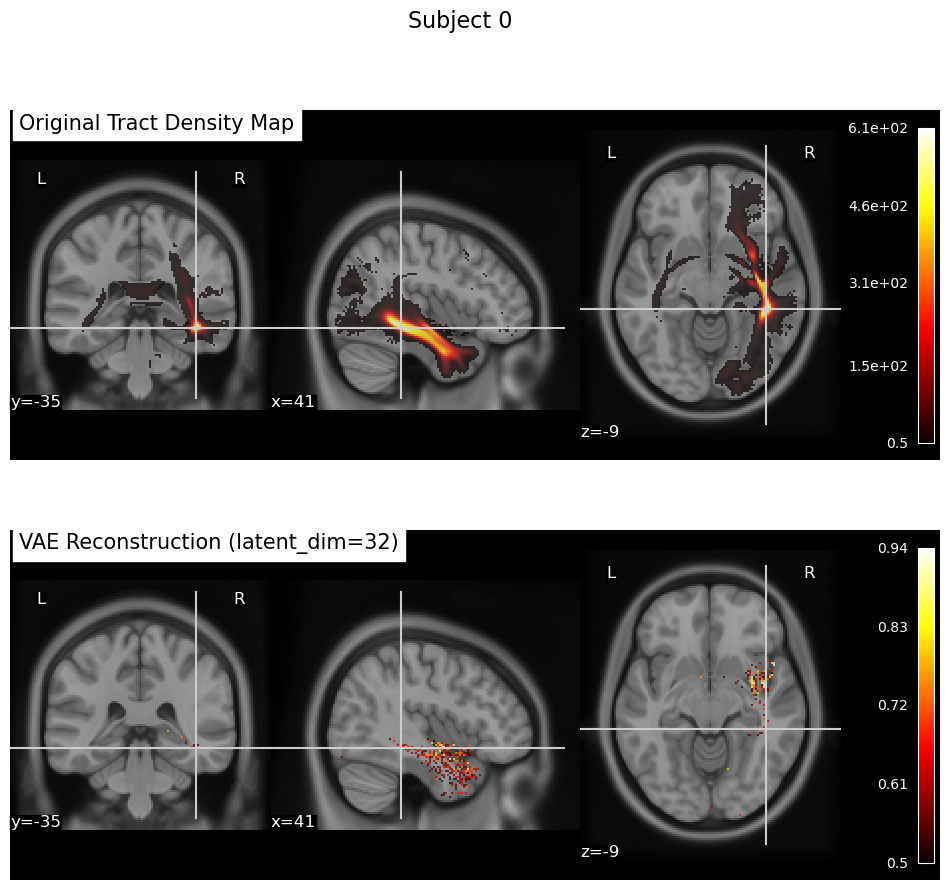

Wektor ukryty (Latent mu) dla tego pacjenta (pierwsze 10 dim):
[19.721737  -1.3779641 -0.6170462  9.2088585 -2.28623   12.472168
 -3.893871  -3.180521  -7.201062  -4.511139 ]


In [ ]:
idx = 0

flat_map = dataset_training.maps[idx]

map_3d = flat_map.reshape(method.shape)

# 3. Rysuj
method.visualize_anatomical(
    map_single=map_3d, 
    title=f"Subject {idx}"
)

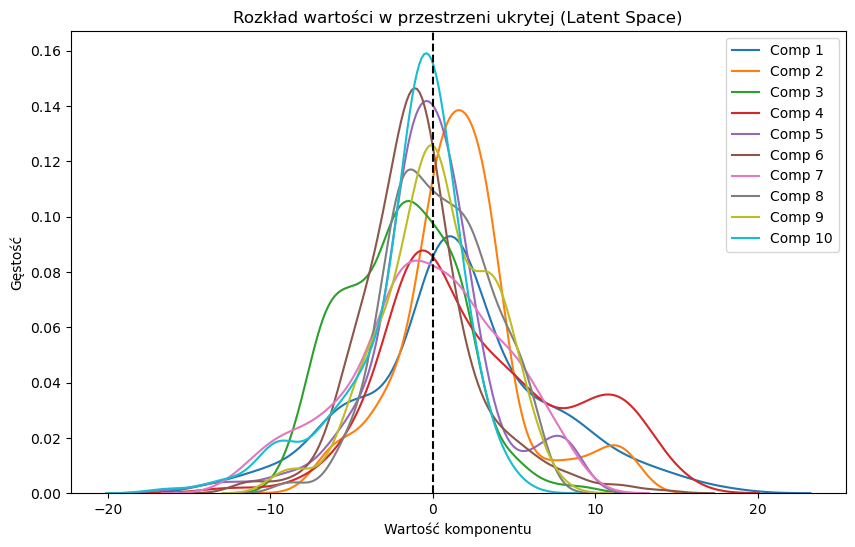

In [21]:
import seaborn as sns

def plot_component_distribution(comps):
    plt.figure(figsize=(10, 6))
    # Rysujemy rozkład dla kilku pierwszych komponentów
    for i in range(10):
        sns.kdeplot(comps[:, i], label=f'Comp {i+1}')
    
    plt.axvline(0, color='black', linestyle='--')
    plt.title("Rozkład wartości w przestrzeni ukrytej (Latent Space)")
    plt.xlabel("Wartość komponentu")
    plt.ylabel("Gęstość")
    plt.legend()
    plt.show()

# Użycie:
plot_component_distribution(comps_testing)

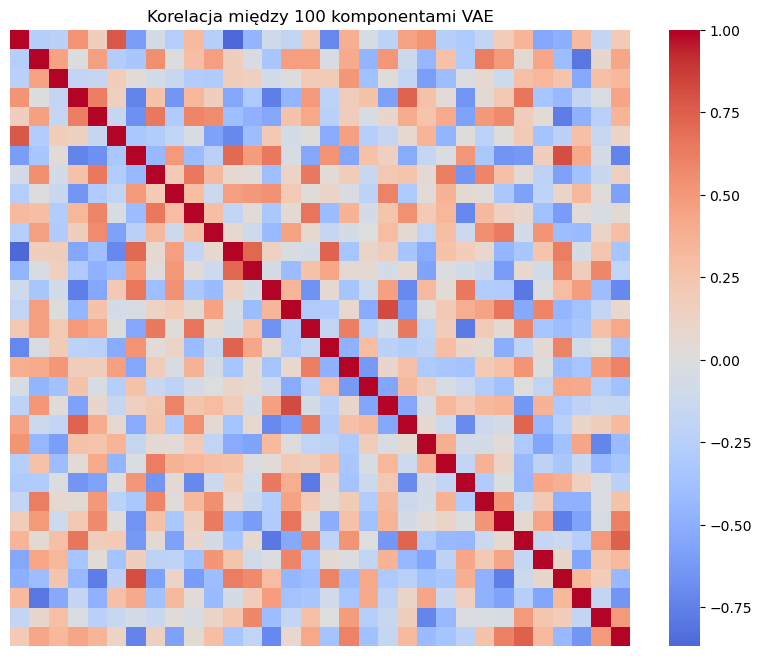

In [22]:
def plot_correlation_matrix(comps):
    plt.figure(figsize=(10, 8))
    corr = np.corrcoef(comps, rowvar=False)
    sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False)
    plt.title("Korelacja między 100 komponentami VAE")
    plt.show()

plot_correlation_matrix(comps_testing)

In [40]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import torch
from nilearn import plotting

def plot_vae_reconstruction(vae_method, raw_map_3d, title="Anatomical Comparison"):
    """
    Zewnętrzna funkcja do rysowania oryginału i rekonstrukcji VAE.
    """
    # 1. Przygotowanie oryginału (musi być 3D do nilearn)
    if raw_map_3d.ndim == 1:
        # Jeśli dostałaś płaski wektor, przywróć mu kształt z modelu
        orig_3d = raw_map_3d.reshape(vae_method.shape)
    else:
        orig_3d = raw_map_3d

    # 2. Przygotowanie danych wejściowych dla VAE (musi być 2D: 1 x Voxels)
    flat_full = orig_3d.reshape(1, -1)
    
    # Maskowanie (jeśli dane są surowe, a model chce zamaskowane)
    if flat_full.shape[1] > vae_method.input_dim:
        map_input = vae_method.mask(flat_full)
    else:
        map_input = flat_full

    # 3. Normalizacja i Rekonstrukcja
    # Zakładamy, że używamy MinMax tak jak w treningu
    input_norm = np.clip(vae_method.MinMax(map_input), 0, 1)
    
    vae_method.model.eval()
    with torch.no_grad():
        tensor_input = torch.Tensor(input_norm).to(vae_method.device)
        # Przejście przez cały model (forward zwraca: recon, mu, logvar)
        recon_norm_flat, _, _ = vae_method.model(tensor_input)

    # 4. Odmaskowanie rekonstrukcji z powrotem do 3D
    # Używamy Twojej poprawionej metody unmask_maps z klasy TD_VAE
    recon_3d = vae_method.unmask_maps(recon_norm_flat.cpu().numpy())[0]

    # 5. Rysowanie (Nilearn)
    affine = vae_method.template.affine
    orig_img = nib.Nifti1Image(orig_3d, affine)
    recon_img = nib.Nifti1Image(recon_3d, affine)

    # Znajdź środek masy dla ładnego widoku
    cut_coords = plotting.find_xyz_cut_coords(orig_img, activation_threshold=orig_3d.max()*0.3)

    fig, axes = plt.subplots(2, 1, figsize=(10, 8))
    
    plotting.plot_roi(orig_img, bg_img=vae_method.template, cut_coords=cut_coords, 
                      title="Oryginalna Mapa TD", axes=axes[0], cmap='hot', alpha=0.7)
    
    plotting.plot_roi(recon_img, bg_img=vae_method.template, cut_coords=cut_coords, 
                      title=f"Rekonstrukcja VAE (dim={vae_method.latent_dim})", axes=axes[1], cmap='hot', alpha=0.7)
    
    plt.suptitle(title)
    plt.show()

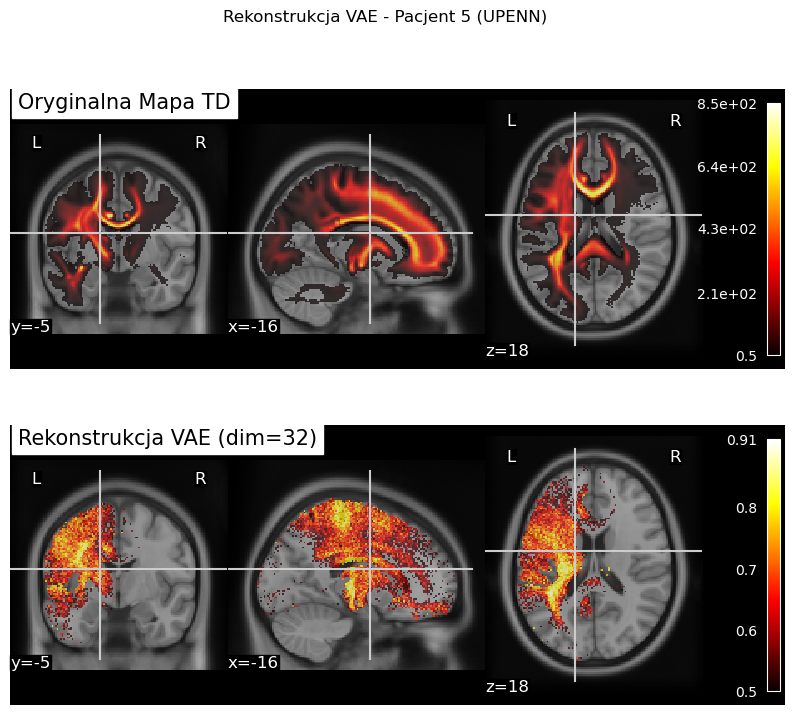

In [48]:
pacjent_test_idx = 5
flat_map_test = dataset_testing.maps[pacjent_test_idx]
raw_3d_test = flat_map_test.reshape(method.shape)

plot_vae_reconstruction(
    vae_method=method, 
    raw_map_3d=raw_3d_test, 
    title=f"Rekonstrukcja VAE - Pacjent {pacjent_test_idx} (UPENN)"
)

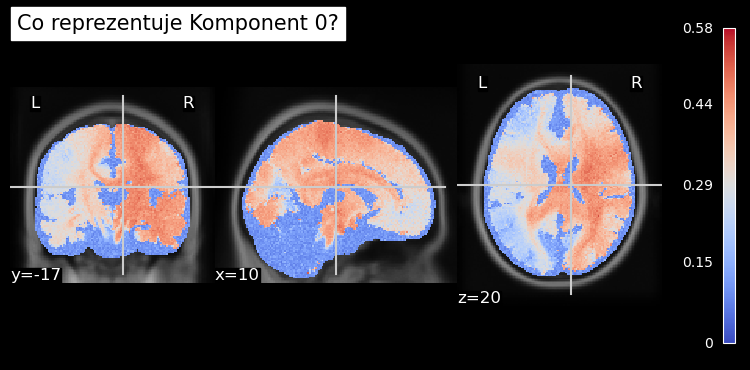

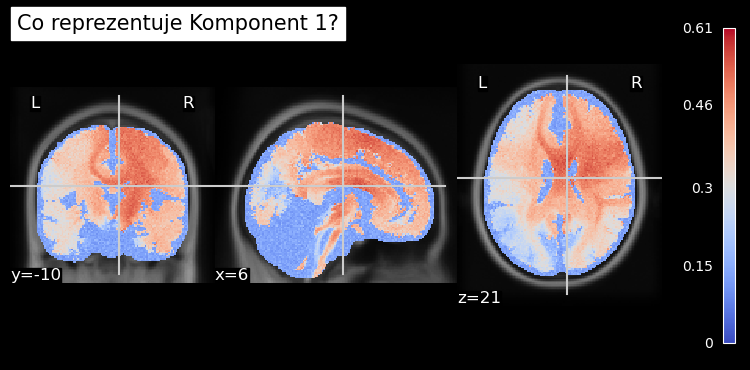

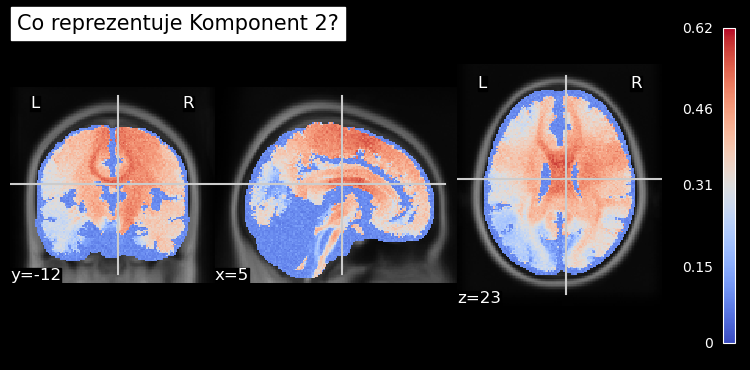

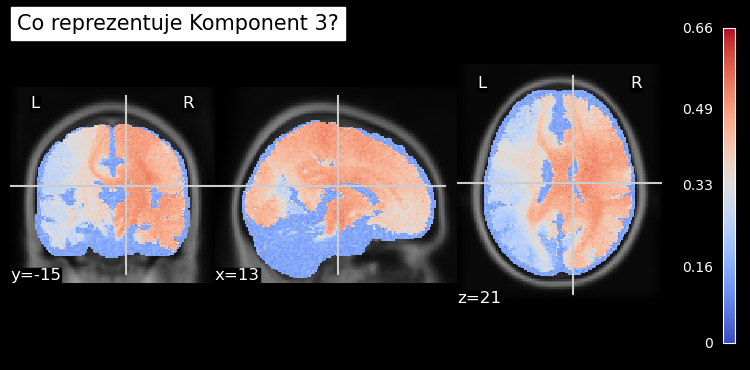

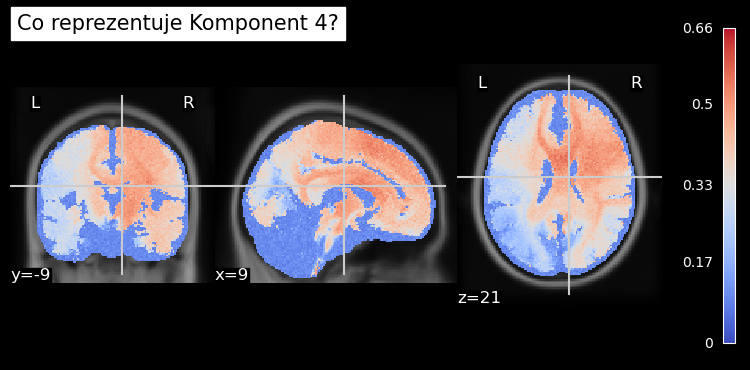

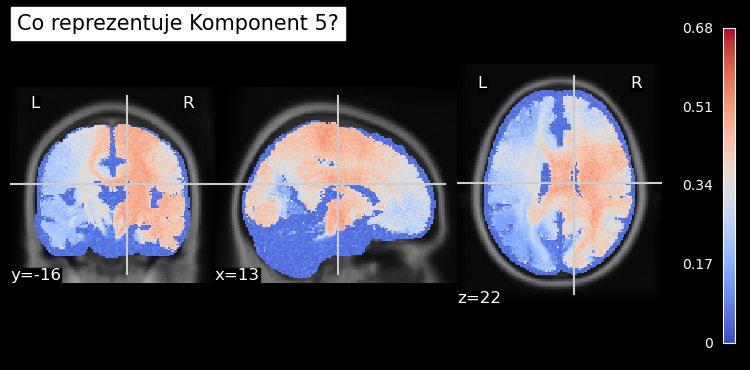

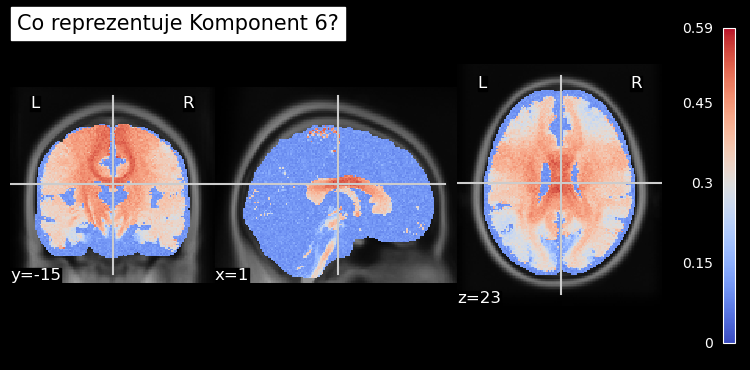

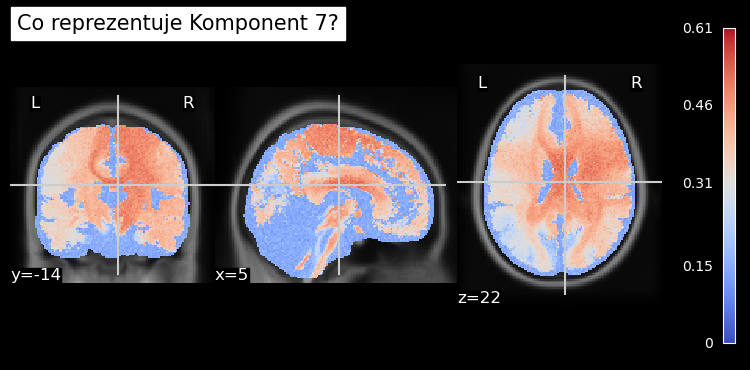

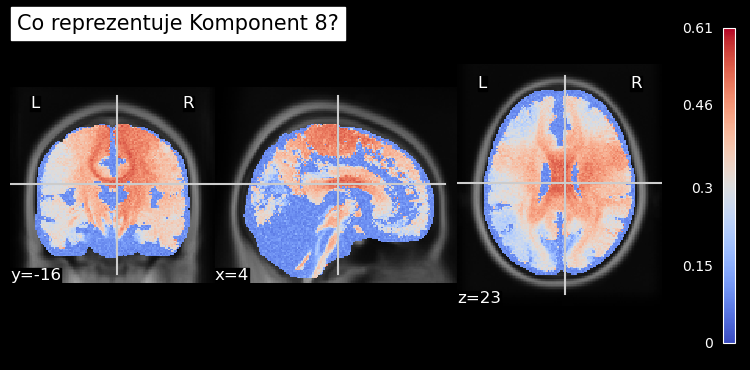

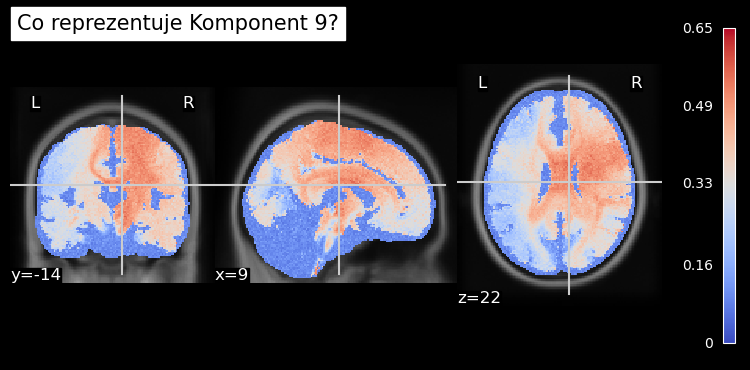

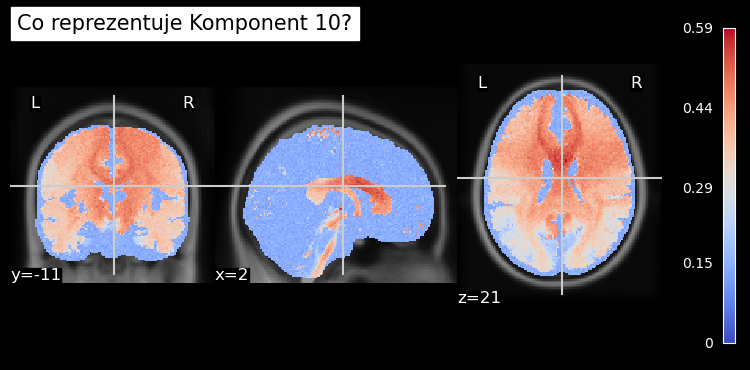

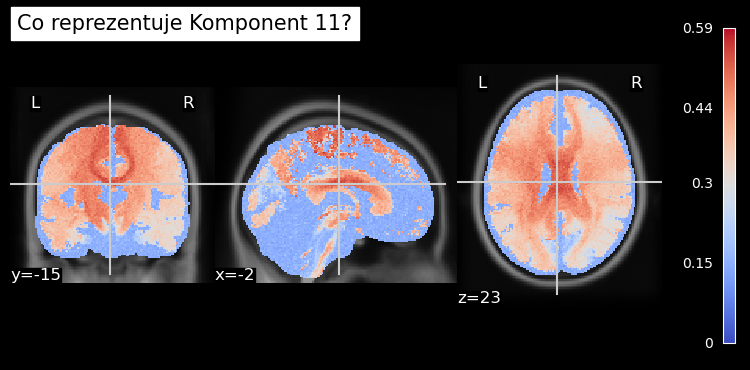

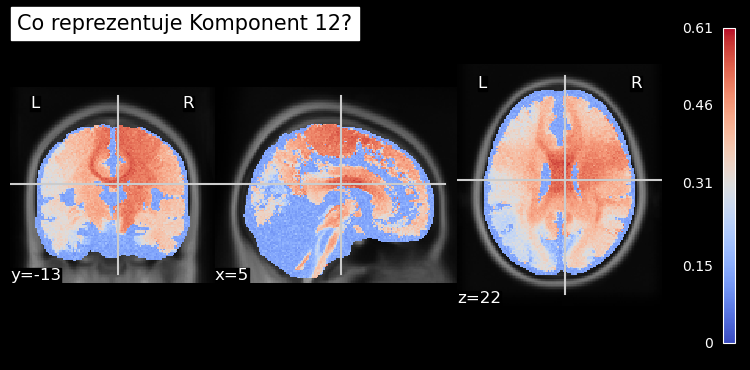

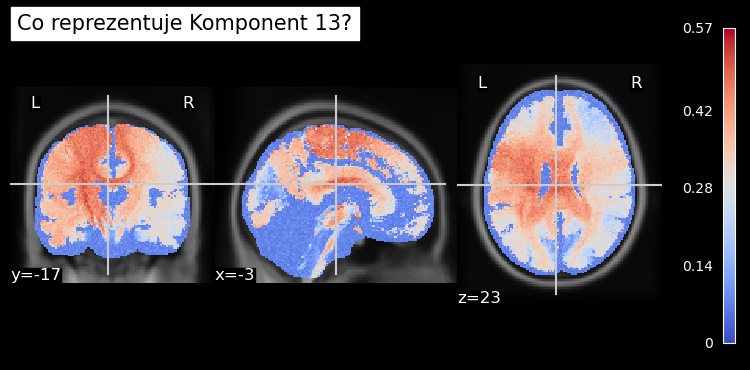

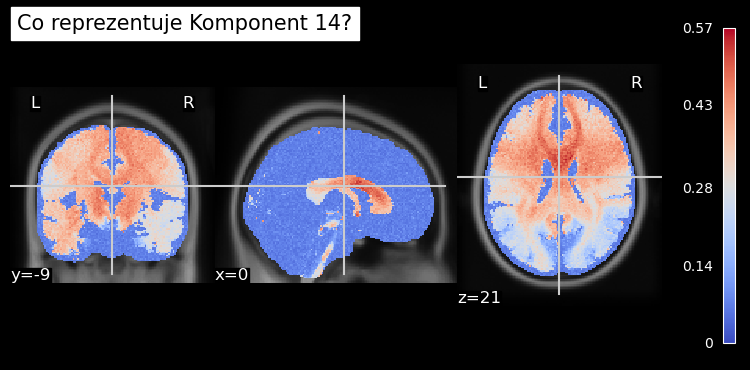

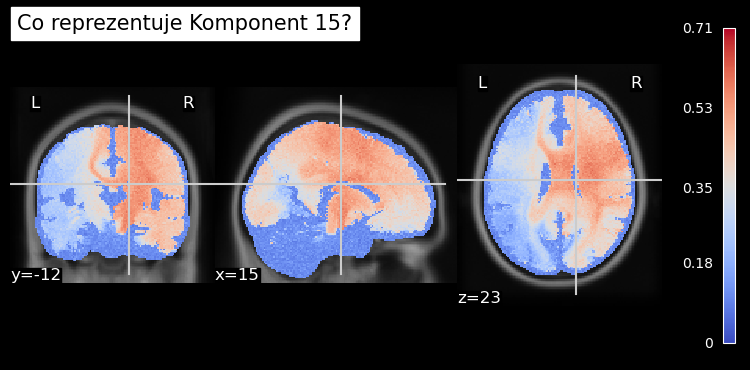

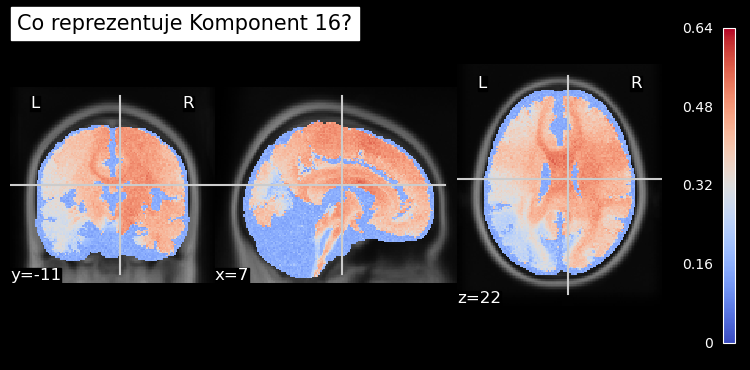

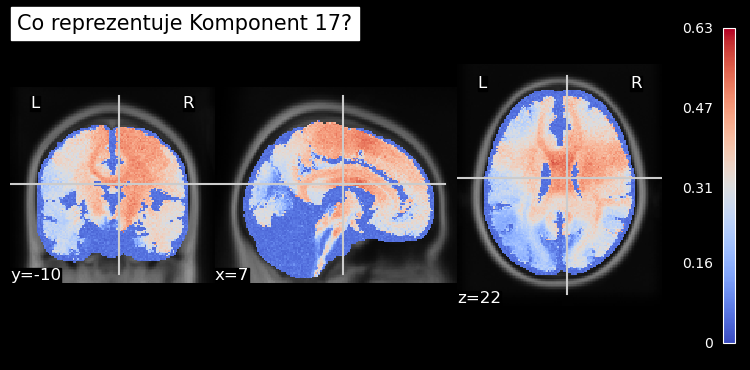

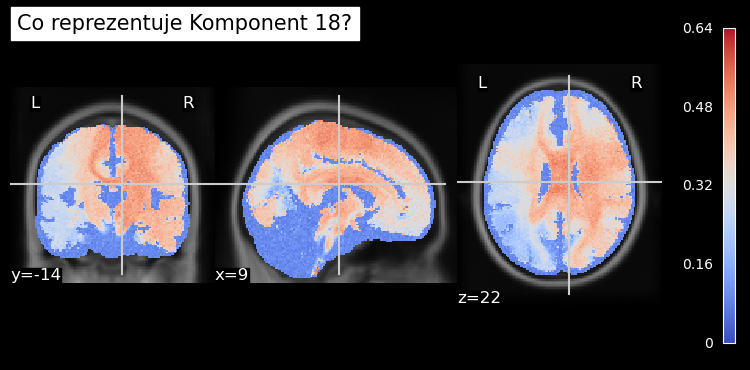

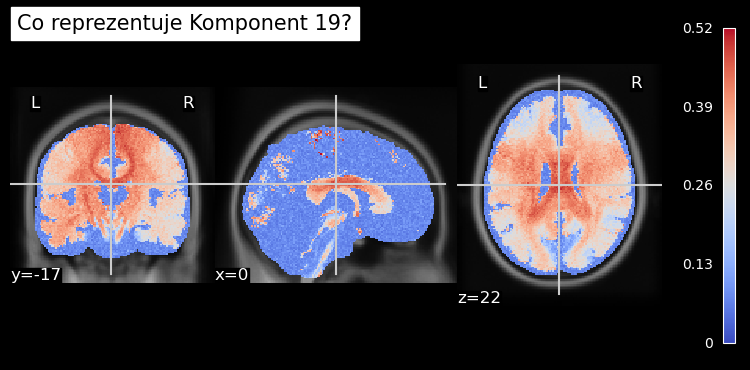

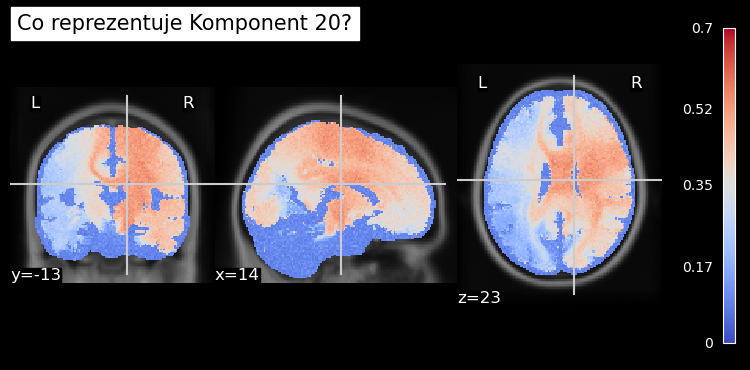

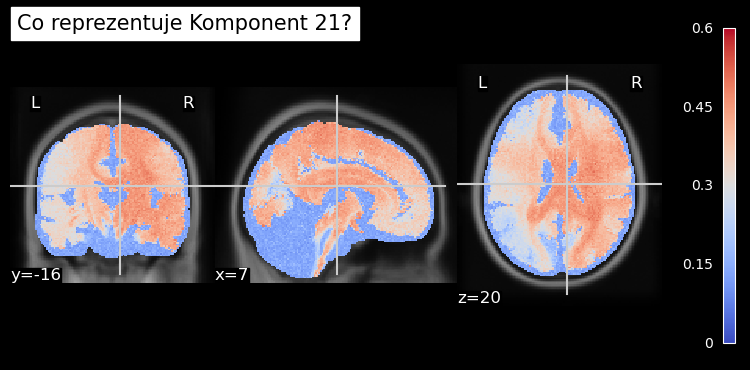

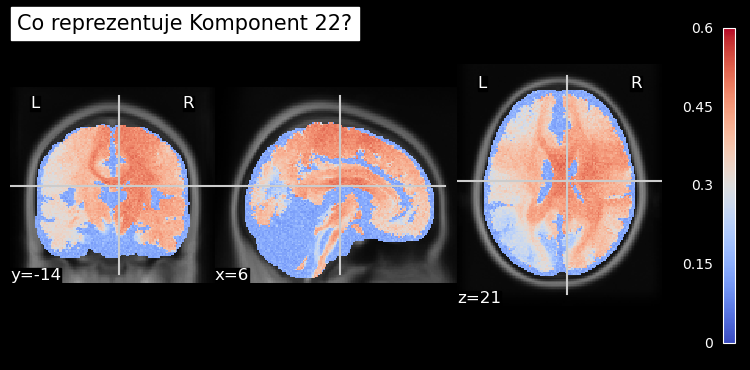

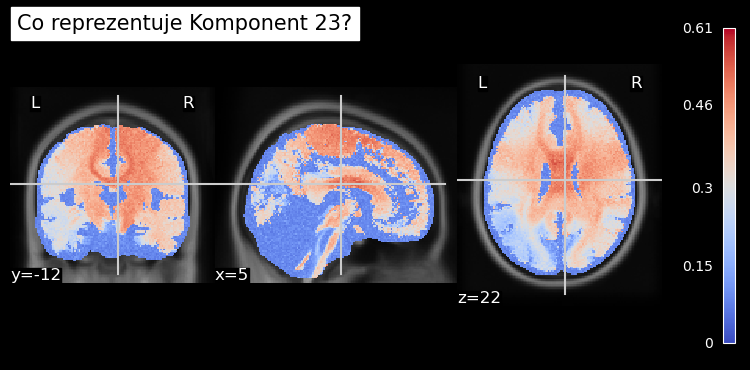

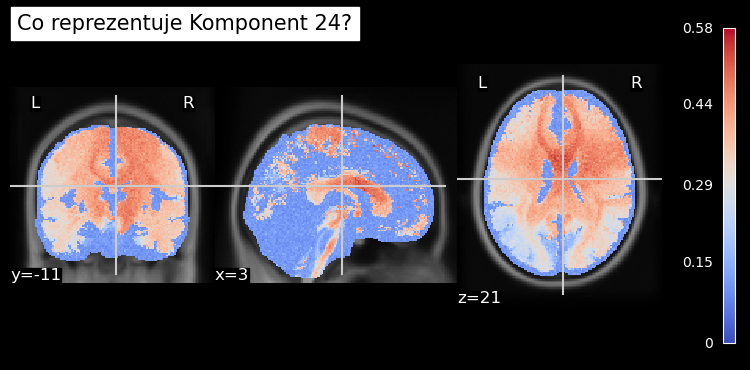

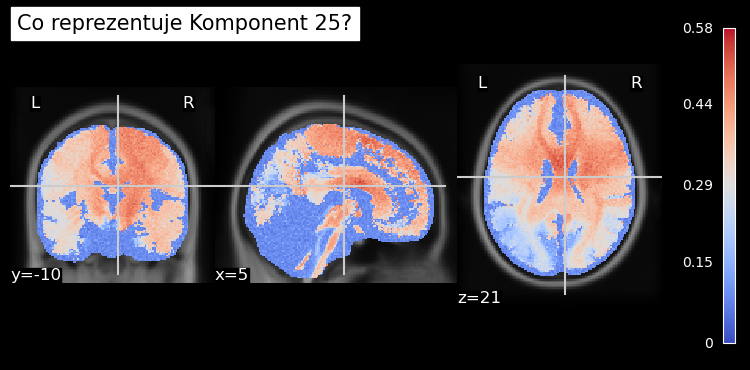

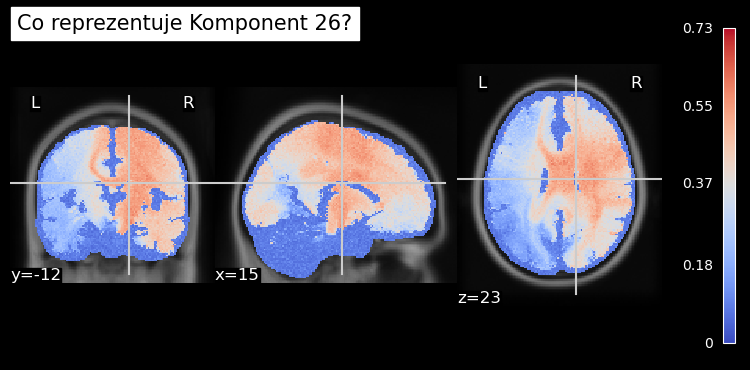

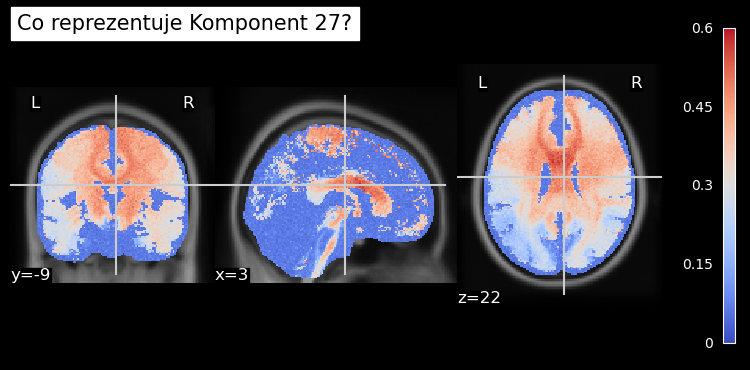

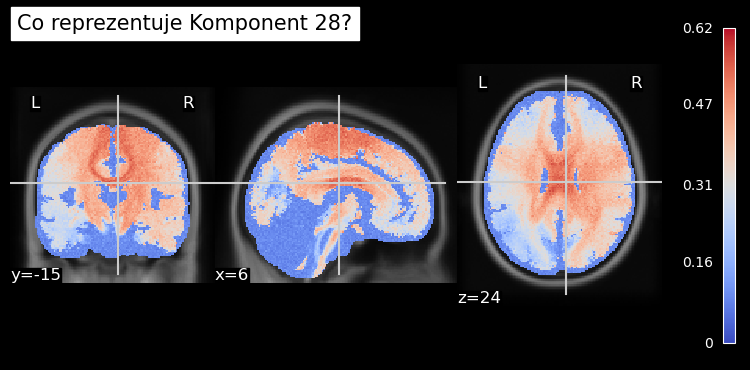

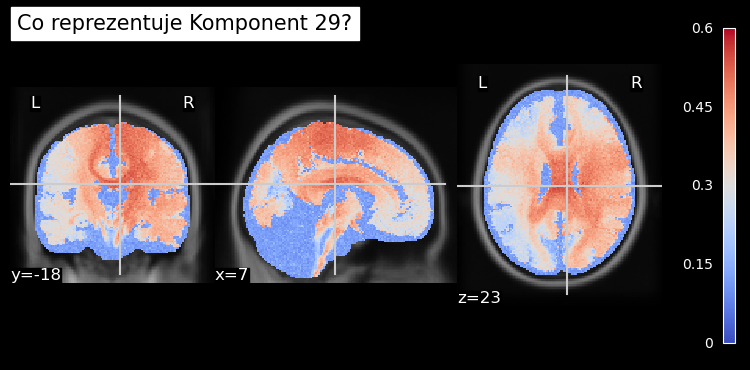

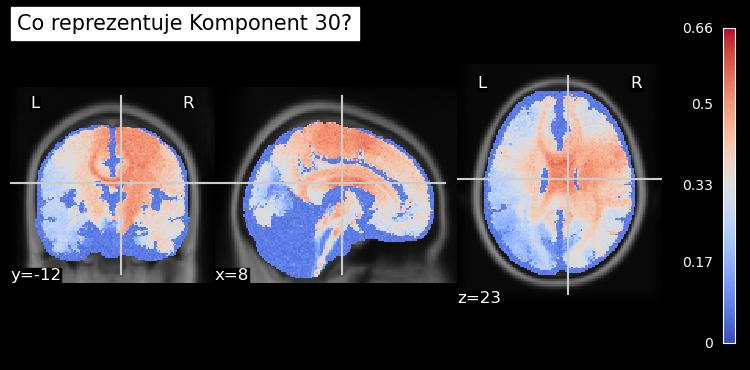

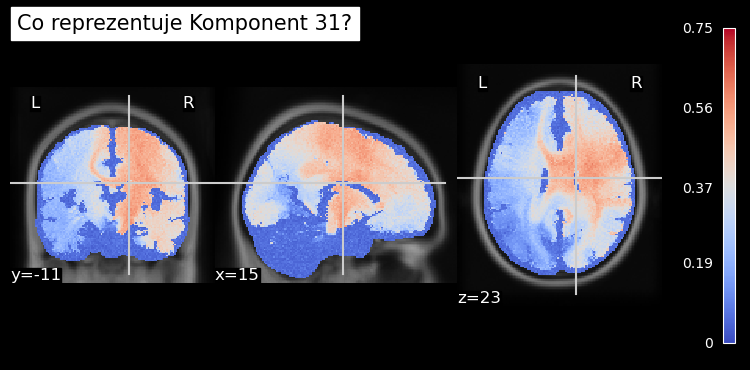

In [46]:
def plot_latent_dimension(vae_method, component_idx=0, value=3.0):
    # Tworzymy wektor zer
    latent_vector = np.zeros((1, vae_method.latent_dim))
    # Ustawiamy wybrany komponent na wysoką wartość
    latent_vector[0, component_idx] = value
    
    # Dekodujemy go do 3D
    decoded_flat = vae_method.decode_maps(latent_vector)
    decoded_3d = vae_method.unmask_maps(decoded_flat)[0]
    
    # Rysujemy
    img = nib.Nifti1Image(decoded_3d, vae_method.template.affine)
    plotting.plot_stat_map(img, bg_img=vae_method.template, 
                          title=f"Co reprezentuje Komponent {component_idx}?", cmap='coolwarm')
    plt.show()

# Wywołanie:
for i in range(32):
    plot_latent_dimension(method, component_idx=i)